In [3]:
import pandas as pd
import zipfile
import urllib.request
import io

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank.zip"

with urllib.request.urlopen(url) as response:
    zip_bytes = response.read()

with zipfile.ZipFile(io.BytesIO(zip_bytes)) as z:
    print(z.namelist())

['bank-full.csv', 'bank-names.txt', 'bank.csv']


In [4]:
with zipfile.ZipFile(io.BytesIO(zip_bytes)) as z:
    with z.open("bank-full.csv") as f:
        df = pd.read_csv(f, sep=";")

print(df.shape)
print(df.head())

(45211, 17)
   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married    unknown      no     1506     yes   no   
4   33       unknown   single    unknown      no        1      no   no   

   contact  day month  duration  campaign  pdays  previous poutcome   y  
0  unknown    5   may       261         1     -1         0  unknown  no  
1  unknown    5   may       151         1     -1         0  unknown  no  
2  unknown    5   may        76         1     -1         0  unknown  no  
3  unknown    5   may        92         1     -1         0  unknown  no  
4  unknown    5   may       198         1     -1         0  unknown  no  


In [5]:
print("\nColumns:")
print(df.columns.tolist())

print("\nTarget counts:")
print(df["y"].value_counts())

print("\nJob counts:")
print(df["job"].value_counts())


Columns:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Target counts:
y
no     39922
yes     5289
Name: count, dtype: int64

Job counts:
job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64


In [6]:
df["age_bin"] = pd.cut(
    df["age"],
    bins=[0, 30, 40, 50, 60, 120],
    labels=[
        "under_30",
        "30_39",
        "40_49",
        "50_59",
        "60_plus"
    ],
    right=False
)

print("\nAge bins:")
print(df["age_bin"].value_counts().sort_index())


Age bins:
age_bin
under_30     5273
30_39       18089
40_49       11655
50_59        8410
60_plus      1784
Name: count, dtype: int64


In [7]:
print("Housing:")
print(df["housing"].value_counts())

print("\nLoan:")
print(df["loan"].value_counts())

Housing:
housing
yes    25130
no     20081
Name: count, dtype: int64

Loan:
loan
no     37967
yes     7244
Name: count, dtype: int64


In [8]:
age_categories = [
    "under_30",
    "30_39",
    "40_49",
    "50_59",
    "60_plus"
]

job_categories = [
    "admin.",
    "blue-collar",
    "entrepreneur",
    "housemaid",
    "management",
    "retired",
    "self-employed",
    "services",
    "student",
    "technician",
    "unemployed",
    "unknown"
]

binary_categories = ["no", "yes"]

In [9]:
age_to_int = {
    category: i
    for i, category in enumerate(age_categories)
}

job_to_int = {
    category: i
    for i, category in enumerate(job_categories)
}

binary_to_int = {
    "no": 0,
    "yes": 1
}

In [10]:
df["age_code"] = df["age_bin"].map(age_to_int).astype(int)
df["job_code"] = df["job"].map(job_to_int).astype(int)
df["housing_code"] = df["housing"].map(binary_to_int).astype(int)
df["loan_code"] = df["loan"].map(binary_to_int).astype(int)

In [11]:
print(
    df[
        [
            "age",
            "age_bin",
            "age_code",
            "job",
            "job_code",
            "housing",
            "housing_code",
            "loan",
            "loan_code"
        ]
    ].head(10)
)

   age   age_bin  age_code           job  job_code housing  housing_code loan  \
0   58     50_59         3    management         4     yes             1   no   
1   44     40_49         2    technician         9     yes             1   no   
2   33     30_39         1  entrepreneur         2     yes             1  yes   
3   47     40_49         2   blue-collar         1     yes             1   no   
4   33     30_39         1       unknown        11      no             0   no   
5   35     30_39         1    management         4     yes             1   no   
6   28  under_30         0    management         4     yes             1  yes   
7   42     40_49         2  entrepreneur         2     yes             1   no   
8   58     50_59         3       retired         5     yes             1   no   
9   43     40_49         2    technician         9     yes             1   no   

   loan_code  
0          0  
1          0  
2          1  
3          0  
4          0  
5          0  
6  

In [12]:
df["qos_address"] = (
    (
        (
            df["age_code"] * len(job_categories)
            + df["job_code"]
        ) * 2
        + df["housing_code"]
    ) * 2
    + df["loan_code"]
)

In [13]:
print(
    df[
        [
            "age_bin",
            "job",
            "housing",
            "loan",
            "qos_address"
        ]
    ].head(20)
)

     age_bin           job housing loan  qos_address
0      50_59    management     yes   no          162
1      40_49    technician     yes   no          134
2      30_39  entrepreneur     yes  yes           59
3      40_49   blue-collar     yes   no          102
4      30_39       unknown      no   no           92
5      30_39    management     yes   no           66
6   under_30    management     yes  yes           19
7      40_49  entrepreneur     yes   no          106
8      50_59       retired     yes   no          166
9      40_49    technician     yes   no          134
10     40_49        admin.     yes   no           98
11  under_30        admin.     yes   no            2
12     50_59    technician     yes   no          182
13     50_59    technician     yes   no          182
14     50_59      services     yes   no          174
15     50_59       retired     yes   no          166
16     40_49        admin.     yes   no           98
17     50_59   blue-collar     yes   no       

In [14]:
print("Minimum address:", df["qos_address"].min())
print("Maximum address:", df["qos_address"].max())
print("Unique addresses actually observed:", df["qos_address"].nunique())

Minimum address: 0
Maximum address: 238
Unique addresses actually observed: 216


In [15]:
num_addresses = (
    len(age_categories)
    * len(job_categories)
    * 2
    * 2
)

print("Logical address space:", num_addresses)

Logical address space: 240


In [18]:
import numpy as np
address_counts = (
    df["qos_address"]
    .value_counts()
    .reindex(range(num_addresses), fill_value=0)
    .sort_index()
)

p_bank = address_counts.to_numpy() / len(df)

print("Number of probabilities:", len(p_bank))
print("Sum:", np.sum(p_bank))
print("Nonzero addresses:", np.count_nonzero(p_bank))

Number of probabilities: 240
Sum: 1.0
Nonzero addresses: 216


In [19]:
for x in range(20):
    print(
        f"x={x:3d}  "
        f"count={address_counts.iloc[x]:5d}  "
        f"p={p_bank[x]:.6f}"
    )

x=  0  count=  218  p=0.004822
x=  1  count=   67  p=0.001482
x=  2  count=  378  p=0.008361
x=  3  count=   88  p=0.001946
x=  4  count=  190  p=0.004203
x=  5  count=   79  p=0.001747
x=  6  count=  715  p=0.015815
x=  7  count=  149  p=0.003296
x=  8  count=   22  p=0.000487
x=  9  count=    8  p=0.000177
x= 10  count=   50  p=0.001106
x= 11  count=   16  p=0.000354
x= 12  count=   16  p=0.000354
x= 13  count=    6  p=0.000133
x= 14  count=   27  p=0.000597
x= 15  count=    6  p=0.000133
x= 16  count=  332  p=0.007343
x= 17  count=   49  p=0.001084
x= 18  count=  330  p=0.007299
x= 19  count=   47  p=0.001040


In [20]:
import math

num_qubits_bank = math.ceil(
    math.log2(num_addresses)
)

quantum_dimension = 2 ** num_qubits_bank

print("Number of logical addresses:", num_addresses)
print("Qubits required:", num_qubits_bank)
print("Quantum basis states:", quantum_dimension)

Number of logical addresses: 240
Qubits required: 8
Quantum basis states: 256


In [21]:
p_bank_padded = np.zeros(quantum_dimension)

p_bank_padded[:num_addresses] = p_bank

print("Shape:", p_bank_padded.shape)
print("Sum:", np.sum(p_bank_padded))

Shape: (256,)
Sum: 1.0


In [22]:
import pennylane as qp
import numpy as np

t_bank = 1.0

exact_bank_phases = t_bank * p_bank_padded
exact_bank_diagonal = np.exp(1j * exact_bank_phases)

bank_wires = list(range(num_qubits_bank))
bank_dev = qp.device("default.qubit", wires=num_qubits_bank)

@qp.qnode(bank_dev)
def exact_bank_oracle():
    for wire in bank_wires:
        qp.Hadamard(wires=wire)

    qp.DiagonalQubitUnitary(
        exact_bank_diagonal,
        wires=bank_wires
    )

    return qp.state()

exact_bank_state = exact_bank_oracle()

print("Exact bank state dimension:", len(exact_bank_state))

Exact bank state dimension: 256


In [23]:
M_bank = 1000

sampled_customers = df.sample(
    n=M_bank,
    replace=True,
    random_state=42
)

bank_samples = sampled_customers["qos_address"].to_numpy()

print(bank_samples[:20])

[ 54  68  86  32 108  50 117  55  86  16  86  64  54  54  38   6  54  86
 172  66]


In [24]:
bank_counts = np.bincount(
    bank_samples,
    minlength=num_addresses
)

p_bank_hat = bank_counts / M_bank

p_bank_hat_padded = np.zeros(quantum_dimension)
p_bank_hat_padded[:num_addresses] = p_bank_hat

print("Estimated distribution sum:", np.sum(p_bank_hat_padded))

Estimated distribution sum: 1.0


In [25]:
estimated_bank_phases = t_bank * p_bank_hat_padded
estimated_bank_diagonal = np.exp(1j * estimated_bank_phases)

@qp.qnode(bank_dev)
def qos_bank_oracle():
    for wire in bank_wires:
        qp.Hadamard(wires=wire)

    qp.DiagonalQubitUnitary(
        estimated_bank_diagonal,
        wires=bank_wires
    )

    return qp.state()

qos_bank_state = qos_bank_oracle()

In [26]:
overlap_bank = np.vdot(
    exact_bank_state,
    qos_bank_state
)

fidelity_bank = np.abs(overlap_bank) ** 2

print("Bank QOS fidelity:", fidelity_bank)

Bank QOS fidelity: 0.9999968175488239


In [27]:
distribution_error = p_bank_hat_padded - p_bank_padded

l1_error = np.sum(
    np.abs(distribution_error)
)

l2_error = np.sqrt(
    np.sum(distribution_error**2)
)

max_error = np.max(
    np.abs(distribution_error)
)

print("L1 error:", l1_error)
print("L2 error:", l2_error)
print("Maximum absolute probability error:", max_error)

L1 error: 0.2556243834465064
L2 error: 0.028543139430912183
Maximum absolute probability error: 0.01046975293623234


In [28]:
observed_in_sample = np.count_nonzero(bank_counts)

print(
    "Addresses observed in full dataset:",
    np.count_nonzero(p_bank)
)

print(
    "Addresses observed in 1000-customer sample:",
    observed_in_sample
)

Addresses observed in full dataset: 216
Addresses observed in 1000-customer sample: 142


In [29]:
absolute_errors = np.abs(
    p_bank_hat - p_bank
)

worst_addresses = np.argsort(
    absolute_errors
)[-10:][::-1]

for x in worst_addresses:
    print(
        f"Address {x:3d} | "
        f"true={p_bank[x]:.6f} | "
        f"estimated={p_bank_hat[x]:.6f} | "
        f"error={absolute_errors[x]:.6f}"
    )

Address  54 | true=0.057530 | estimated=0.068000 | error=0.010470
Address  98 | true=0.015284 | estimated=0.006000 | error=0.009284
Address 212 | true=0.021057 | estimated=0.013000 | error=0.008057
Address  86 | true=0.035854 | estimated=0.042000 | error=0.006146
Address  88 | true=0.005176 | estimated=0.011000 | error=0.005824
Address  78 | true=0.023468 | estimated=0.029000 | error=0.005532
Address 124 | true=0.006503 | estimated=0.012000 | error=0.005497
Address  66 | true=0.044038 | estimated=0.039000 | error=0.005038
Address 135 | true=0.004778 | estimated=0.009000 | error=0.004222
Address 103 | true=0.007122 | estimated=0.003000 | error=0.004122


In [33]:
def decode_qos_address(address):
    x = int(address)

    loan_code = x % 2
    x //= 2

    housing_code = x % 2
    x //= 2

    job_code = x % len(job_categories)
    x //= len(job_categories)

    age_code = x

    return {
        "age_bin": age_categories[age_code],
        "job": job_categories[job_code],
        "housing": binary_categories[housing_code],
        "loan": binary_categories[loan_code]
    }

In [34]:
for x in worst_addresses:
    profile = decode_qos_address(x)

    print(
        f"Address {x:3d} | "
        f"{profile} | "
        f"true={p_bank[x]:.6f} | "
        f"estimated={p_bank_hat[x]:.6f} | "
        f"error={absolute_errors[x]:.6f}"
    )

Address  54 | {'age_bin': '30_39', 'job': 'blue-collar', 'housing': 'yes', 'loan': 'no'} | true=0.057530 | estimated=0.068000 | error=0.010470
Address  98 | {'age_bin': '40_49', 'job': 'admin.', 'housing': 'yes', 'loan': 'no'} | true=0.015284 | estimated=0.006000 | error=0.009284
Address 212 | {'age_bin': '60_plus', 'job': 'retired', 'housing': 'no', 'loan': 'no'} | true=0.021057 | estimated=0.013000 | error=0.008057
Address  86 | {'age_bin': '30_39', 'job': 'technician', 'housing': 'yes', 'loan': 'no'} | true=0.035854 | estimated=0.042000 | error=0.006146
Address  88 | {'age_bin': '30_39', 'job': 'unemployed', 'housing': 'no', 'loan': 'no'} | true=0.005176 | estimated=0.011000 | error=0.005824
Address  78 | {'age_bin': '30_39', 'job': 'services', 'housing': 'yes', 'loan': 'no'} | true=0.023468 | estimated=0.029000 | error=0.005532
Address 124 | {'age_bin': '40_49', 'job': 'services', 'housing': 'no', 'loan': 'no'} | true=0.006503 | estimated=0.012000 | error=0.005497
Address  66 | {'a

In [35]:
sample_sizes_bank = [
    100,
    250,
    500,
    1000,
    2500,
    5000,
    10000,
    20000
]

num_trials_bank = 50

results = []

addresses_full = np.count_nonzero(p_bank)

for M_test in sample_sizes_bank:

    trial_fidelity = []
    trial_l1 = []
    trial_l2 = []
    trial_max = []
    trial_coverage = []

    for trial in range(num_trials_bank):

        sampled = df.sample(
            n=M_test,
            replace=True
        )

        samples_test = sampled["qos_address"].to_numpy()

        counts_test = np.bincount(
            samples_test,
            minlength=num_addresses
        )

        p_hat_test = counts_test / M_test

        p_hat_padded_test = np.zeros(quantum_dimension)
        p_hat_padded_test[:num_addresses] = p_hat_test

        # ----------------------------
        # Distribution errors
        # ----------------------------
        diff = p_hat_padded_test - p_bank_padded

        l1 = np.sum(np.abs(diff))
        l2 = np.sqrt(np.sum(diff**2))
        max_err = np.max(np.abs(diff))

        # ----------------------------
        # Address coverage
        # ----------------------------
        observed = np.count_nonzero(counts_test)

        coverage = observed / addresses_full

        # ----------------------------
        # Quantum fidelity
        # ----------------------------
        phases_test = t_bank * p_hat_padded_test

        diagonal_test = np.exp(
            1j * phases_test
        )

        state_test = (
            diagonal_test
            / np.sqrt(quantum_dimension)
        )

        overlap = np.vdot(
            exact_bank_state,
            state_test
        )

        fidelity = np.abs(overlap) ** 2

        trial_fidelity.append(fidelity)
        trial_l1.append(l1)
        trial_l2.append(l2)
        trial_max.append(max_err)
        trial_coverage.append(coverage)

    results.append({
        "M": M_test,

        "fidelity_mean": np.mean(trial_fidelity),
        "fidelity_std": np.std(trial_fidelity),

        "l1_mean": np.mean(trial_l1),
        "l1_std": np.std(trial_l1),

        "l2_mean": np.mean(trial_l2),
        "l2_std": np.std(trial_l2),

        "max_mean": np.mean(trial_max),
        "max_std": np.std(trial_max),

        "coverage_mean": np.mean(trial_coverage),
        "coverage_std": np.std(trial_coverage)
    })

In [36]:
results_df = pd.DataFrame(results)

print(results_df)

       M  fidelity_mean  fidelity_std   l1_mean    l1_std   l2_mean    l2_std  \
0    100       0.999962  7.434211e-06  0.824861  0.047338  0.098404  0.009455   
1    250       0.999985  2.629263e-06  0.548168  0.033672  0.062578  0.005367   
2    500       0.999992  1.463317e-06  0.398881  0.025441  0.044972  0.004209   
3   1000       0.999996  7.918667e-07  0.281843  0.018665  0.031560  0.003009   
4   2500       0.999998  2.805920e-07  0.176902  0.011171  0.019676  0.001816   
5   5000       0.999999  1.535081e-07  0.126024  0.007721  0.013801  0.001380   
6  10000       1.000000  8.719853e-08  0.088418  0.006477  0.009927  0.001083   
7  20000       1.000000  3.755043e-08  0.063005  0.003954  0.007024  0.000668   

   max_mean   max_std  coverage_mean  coverage_std  
0  0.039655  0.011682       0.255185      0.017461  
1  0.023775  0.006256       0.413704      0.022043  
2  0.016510  0.003718       0.545370      0.023967  
3  0.011929  0.002863       0.649907      0.023183  
4  0.

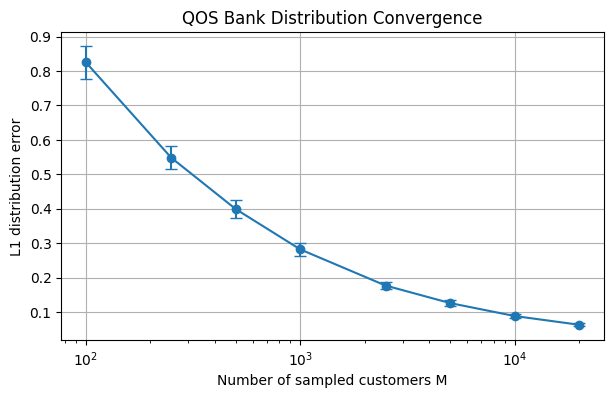

In [40]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 4))

plt.errorbar(
    results_df["M"],
    results_df["l1_mean"],
    yerr=results_df["l1_std"],
    marker="o",
    capsize=4
)

plt.xscale("log")

plt.xlabel("Number of sampled customers M")
plt.ylabel("L1 distribution error")
plt.title("QOS Bank Distribution Convergence")

plt.grid(True)

plt.show()

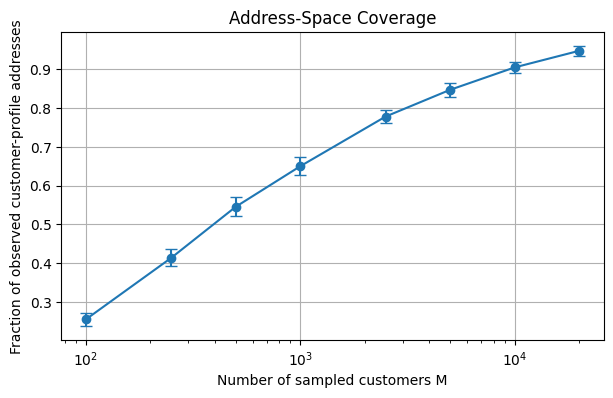

In [41]:
plt.figure(figsize=(7, 4))

plt.errorbar(
    results_df["M"],
    results_df["coverage_mean"],
    yerr=results_df["coverage_std"],
    marker="o",
    capsize=4
)

plt.xscale("log")

plt.xlabel("Number of sampled customers M")
plt.ylabel("Fraction of observed customer-profile addresses")
plt.title("Address-Space Coverage")

plt.grid(True)

plt.show()

In [42]:
df_yes = df[df["y"] == "yes"]
df_no = df[df["y"] == "no"]

print("Yes samples:", len(df_yes))
print("No samples:", len(df_no))

Yes samples: 5289
No samples: 39922


In [43]:
counts_yes = (
    df_yes["qos_address"]
    .value_counts()
    .reindex(range(num_addresses), fill_value=0)
    .sort_index()
)

counts_no = (
    df_no["qos_address"]
    .value_counts()
    .reindex(range(num_addresses), fill_value=0)
    .sort_index()
)

p_yes = counts_yes.to_numpy() / len(df_yes)
p_no = counts_no.to_numpy() / len(df_no)

In [44]:
class_l1 = np.sum(np.abs(p_yes - p_no))
class_l2 = np.sqrt(np.sum((p_yes - p_no) ** 2))

print("L1 distance between yes/no distributions:", class_l1)
print("L2 distance between yes/no distributions:", class_l2)

L1 distance between yes/no distributions: 0.5578923142896658
L2 distance between yes/no distributions: 0.09163165270535291


In [45]:
class_diff = p_yes - p_no
absolute_class_diff = np.abs(class_diff)

most_different = np.argsort(
    absolute_class_diff
)[-15:][::-1]

for x in most_different:
    profile = decode_qos_address(x)

    print(
        f"Address {x:3d} | "
        f"{profile} | "
        f"p_yes={p_yes[x]:.5f} | "
        f"p_no={p_no[x]:.5f} | "
        f"diff={class_diff[x]:+.5f}"
    )

Address 212 | {'age_bin': '60_plus', 'job': 'retired', 'housing': 'no', 'loan': 'no'} | p_yes=0.07109 | p_no=0.01443 | diff=+0.05666
Address  54 | {'age_bin': '30_39', 'job': 'blue-collar', 'housing': 'yes', 'loan': 'no'} | p_yes=0.02968 | p_no=0.06122 | diff=-0.03154
Address  32 | {'age_bin': 'under_30', 'job': 'student', 'housing': 'no', 'loan': 'no'} | p_yes=0.03876 | p_no=0.00807 | diff=+0.03069
Address  64 | {'age_bin': '30_39', 'job': 'management', 'housing': 'no', 'loan': 'no'} | p_yes=0.06504 | p_no=0.03732 | diff=+0.02772
Address 102 | {'age_bin': '40_49', 'job': 'blue-collar', 'housing': 'yes', 'loan': 'no'} | p_yes=0.02269 | p_no=0.04186 | diff=-0.01917
Address  16 | {'age_bin': 'under_30', 'job': 'management', 'housing': 'no', 'loan': 'no'} | p_yes=0.02193 | p_no=0.00541 | diff=+0.01652
Address 150 | {'age_bin': '50_59', 'job': 'blue-collar', 'housing': 'yes', 'loan': 'no'} | p_yes=0.00605 | p_no=0.01869 | diff=-0.01264
Address 112 | {'age_bin': '40_49', 'job': 'management'

In [46]:
p_yes_padded = np.zeros(quantum_dimension)
p_no_padded = np.zeros(quantum_dimension)

p_yes_padded[:num_addresses] = p_yes
p_no_padded[:num_addresses] = p_no

In [47]:
t_class = 1.0

yes_phases = t_class * p_yes_padded
no_phases = t_class * p_no_padded

yes_diagonal = np.exp(1j * yes_phases)
no_diagonal = np.exp(1j * no_phases)

In [48]:
yes_state = yes_diagonal / np.sqrt(quantum_dimension)
no_state = no_diagonal / np.sqrt(quantum_dimension)

In [49]:
class_overlap = np.vdot(
    yes_state,
    no_state
)

class_fidelity = np.abs(class_overlap) ** 2

print("Yes/No quantum-state overlap:", class_overlap)
print("Yes/No quantum-state fidelity:", class_fidelity)

Yes/No quantum-state overlap: (0.9999836029908756+1.2793728798891554e-07j)
Yes/No quantum-state fidelity: 0.9999672062506296


In [50]:
t_values = [
    1,
    2,
    5,
    10,
    20,
    50,
    100
]

class_fidelities = []

for t_test in t_values:

    yes_state_test = (
        np.exp(1j * t_test * p_yes_padded)
        / np.sqrt(quantum_dimension)
    )

    no_state_test = (
        np.exp(1j * t_test * p_no_padded)
        / np.sqrt(quantum_dimension)
    )

    overlap = np.vdot(
        yes_state_test,
        no_state_test
    )

    fidelity = np.abs(overlap) ** 2

    class_fidelities.append(fidelity)

    print(
        f"t={t_test:3d}   "
        f"Yes/No fidelity={fidelity:.8f}"
    )

t=  1   Yes/No fidelity=0.99996721
t=  2   Yes/No fidelity=0.99986888
t=  5   Yes/No fidelity=0.99918287
t= 10   Yes/No fidelity=0.99676505
t= 20   Yes/No fidelity=0.98757835
t= 50   Yes/No fidelity=0.94042579
t=100   Yes/No fidelity=0.87040320


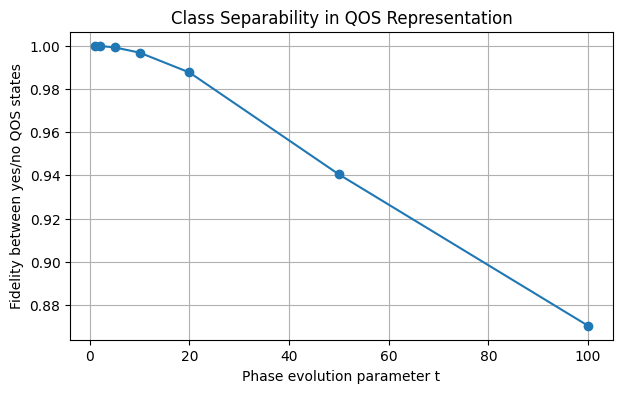

In [51]:
plt.figure(figsize=(7, 4))

plt.plot(
    t_values,
    class_fidelities,
    marker="o"
)

plt.xlabel("Phase evolution parameter t")
plt.ylabel("Fidelity between yes/no QOS states")
plt.title("Class Separability in QOS Representation")

plt.grid(True)

plt.show()

In [52]:
trace_distances = [
    np.sqrt(1 - F)
    for F in class_fidelities
]

for t_test, F, D in zip(
    t_values,
    class_fidelities,
    trace_distances
):
    print(
        f"t={t_test:3d}   "
        f"Fidelity={F:.8f}   "
        f"Trace distance={D:.8f}"
    )

t=  1   Fidelity=0.99996721   Trace distance=0.00572658
t=  2   Fidelity=0.99986888   Trace distance=0.01145079
t=  5   Fidelity=0.99918287   Trace distance=0.02858552
t= 10   Fidelity=0.99676505   Trace distance=0.05687661
t= 20   Fidelity=0.98757835   Trace distance=0.11145245
t= 50   Fidelity=0.94042579   Trace distance=0.24407829
t=100   Fidelity=0.87040320   Trace distance=0.35999555


In [53]:
success_probabilities = [
    (1 + D) / 2
    for D in trace_distances
]

for t_test, P in zip(
    t_values,
    success_probabilities
):
    print(
        f"t={t_test:3d}   "
        f"Optimal discrimination success={P:.6f}"
    )

t=  1   Optimal discrimination success=0.502863
t=  2   Optimal discrimination success=0.505725
t=  5   Optimal discrimination success=0.514293
t= 10   Optimal discrimination success=0.528438
t= 20   Optimal discrimination success=0.555726
t= 50   Optimal discrimination success=0.622039
t=100   Optimal discrimination success=0.679998


In [49]:
rng = np.random.default_rng(42)

yes_indices = df.index[df["y"] == "yes"].to_numpy()
no_indices = df.index[df["y"] == "no"].to_numpy()

rng.shuffle(yes_indices)
rng.shuffle(no_indices)

yes_split = int(0.8 * len(yes_indices))
no_split = int(0.8 * len(no_indices))

train_indices = np.concatenate([
    yes_indices[:yes_split],
    no_indices[:no_split]
])

test_indices = np.concatenate([
    yes_indices[yes_split:],
    no_indices[no_split:]
])

train_df = df.loc[train_indices]
test_df = df.loc[test_indices]

print("Train size:", len(train_df))
print("Test size:", len(test_df))

print("\nTrain labels:")
print(train_df["y"].value_counts())

print("\nTest labels:")
print(test_df["y"].value_counts())

Train size: 36168
Test size: 9043

Train labels:
y
no     31937
yes     4231
Name: count, dtype: int64

Test labels:
y
no     7985
yes    1058
Name: count, dtype: int64


In [51]:
alpha = 1.0

train_yes = train_df[train_df["y"] == "yes"]
train_no = train_df[train_df["y"] == "no"]

counts_yes_train = np.bincount(
    train_yes["qos_address"].to_numpy(),
    minlength=num_addresses
)

counts_no_train = np.bincount(
    train_no["qos_address"].to_numpy(),
    minlength=num_addresses
)

p_yes_train = (
    counts_yes_train + alpha
) / (
    counts_yes_train.sum()
    + alpha * num_addresses
)

p_no_train = (
    counts_no_train + alpha
) / (
    counts_no_train.sum()
    + alpha * num_addresses
)

In [52]:
def predict_from_address(address):
    if p_yes_train[address] > p_no_train[address]:
        return "yes"
    else:
        return "no"

In [53]:
test_predictions = np.array([
    predict_from_address(x)
    for x in test_df["qos_address"].to_numpy()
])

true_labels = test_df["y"].to_numpy()

In [54]:
yes_mask = true_labels == "yes"
no_mask = true_labels == "no"

yes_accuracy = np.mean(
    test_predictions[yes_mask] == "yes"
)

no_accuracy = np.mean(
    test_predictions[no_mask] == "no"
)

balanced_accuracy = (
    yes_accuracy + no_accuracy
) / 2

overall_accuracy = np.mean(
    test_predictions == true_labels
)

print("Yes-class accuracy:", yes_accuracy)
print("No-class accuracy:", no_accuracy)
print("Balanced accuracy:", balanced_accuracy)
print("Overall accuracy:", overall_accuracy)

Yes-class accuracy: 0.558601134215501
No-class accuracy: 0.7005635566687539
Balanced accuracy: 0.6295823454421274
Overall accuracy: 0.6839544398982639


In [55]:
prior_yes = len(train_yes) / len(train_df)
prior_no = len(train_no) / len(train_df)

print("Prior yes:", prior_yes)
print("Prior no:", prior_no)

Prior yes: 0.11698186241981863
Prior no: 0.8830181375801813


In [56]:
def predict_from_address_with_priors(address):
    score_yes = p_yes_train[address] * prior_yes
    score_no = p_no_train[address] * prior_no

    if score_yes > score_no:
        return "yes"
    else:
        return "no"

In [57]:
test_predictions_prior = np.array([
    predict_from_address_with_priors(x)
    for x in test_df["qos_address"].to_numpy()
])

yes_accuracy_prior = np.mean(
    test_predictions_prior[yes_mask] == "yes"
)

no_accuracy_prior = np.mean(
    test_predictions_prior[no_mask] == "no"
)

balanced_accuracy_prior = (
    yes_accuracy_prior + no_accuracy_prior
) / 2

overall_accuracy_prior = np.mean(
    test_predictions_prior == true_labels
)

print("Yes-class accuracy:", yes_accuracy_prior)
print("No-class accuracy:", no_accuracy_prior)
print("Balanced accuracy:", balanced_accuracy_prior)
print("Overall accuracy:", overall_accuracy_prior)

Yes-class accuracy: 0.000945179584120983
No-class accuracy: 0.9997495303694427
Balanced accuracy: 0.5003473549767818
Overall accuracy: 0.8828928452947031


In [58]:
t_classifier = 20.0

def qos_phase_score(address, p_class, t):
    return np.cos(t * p_class[address])

def predict_qos_phase(address, t):
    score_yes = qos_phase_score(
        address,
        p_yes_train,
        t
    )

    score_no = qos_phase_score(
        address,
        p_no_train,
        t
    )

    if score_yes < score_no:
        return "yes"
    else:
        return "no"

In [59]:
qos_predictions = np.array([
    predict_qos_phase(x, t_classifier)
    for x in test_df["qos_address"].to_numpy()
])

yes_accuracy_qos = np.mean(
    qos_predictions[yes_mask] == "yes"
)

no_accuracy_qos = np.mean(
    qos_predictions[no_mask] == "no"
)

balanced_accuracy_qos = (
    yes_accuracy_qos + no_accuracy_qos
) / 2

overall_accuracy_qos = np.mean(
    qos_predictions == true_labels
)

print("Yes-class accuracy:", yes_accuracy_qos)
print("No-class accuracy:", no_accuracy_qos)
print("Balanced accuracy:", balanced_accuracy_qos)
print("Overall accuracy:", overall_accuracy_qos)

Yes-class accuracy: 0.558601134215501
No-class accuracy: 0.7005635566687539
Balanced accuracy: 0.6295823454421274
Overall accuracy: 0.6839544398982639


In [60]:
t_values_classifier = [
    1,
    2,
    5,
    10,
    20,
    50,
    100
]

for t_test in t_values_classifier:

    preds = np.array([
        predict_qos_phase(x, t_test)
        for x in test_df["qos_address"].to_numpy()
    ])

    yes_acc = np.mean(
        preds[yes_mask] == "yes"
    )

    no_acc = np.mean(
        preds[no_mask] == "no"
    )

    bal_acc = (yes_acc + no_acc) / 2

    print(
        f"t={t_test:3d}   "
        f"Yes={yes_acc:.4f}   "
        f"No={no_acc:.4f}   "
        f"Balanced={bal_acc:.4f}"
    )

t=  1   Yes=0.5586   No=0.7006   Balanced=0.6296
t=  2   Yes=0.5586   No=0.7006   Balanced=0.6296
t=  5   Yes=0.5586   No=0.7006   Balanced=0.6296
t= 10   Yes=0.5586   No=0.7006   Balanced=0.6296
t= 20   Yes=0.5586   No=0.7006   Balanced=0.6296
t= 50   Yes=0.5586   No=0.7006   Balanced=0.6296
t=100   Yes=0.4716   No=0.6319   Balanced=0.5518


In [61]:
df.to_csv("bank_marketing_qos_encoded.csv", index=False)